In [1]:
# Some stuff
import pandas as pd
import numpy as np

In [2]:
# Ensemble Learners
from sklearn.ensemble import (
    AdaBoostClassifier,          # Adaptive Boosting
    GradientBoostingClassifier,  # Gradient Boosting
    RandomForestClassifier,      # Random Forest
)

# Simple Learners
from sklearn.linear_model import LogisticRegression   # Logistic Regression
from sklearn.tree import DecisionTreeClassifier       # Decision Tree

# Other stuff
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
# ==========================================
# STEP 1: Load the Dataset
# ==========================================
# Loading the Student Mathematics Performance dataset from Kaggle
df = pd.read_csv('/kaggle/input/datasets/janiobachmann/math-students/student-mat.csv')

print(f'Dataset successfully loaded! Original shape: {df.shape}')

print(df.head(100))

Dataset successfully loaded! Original shape: (395, 33)
   school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0      GP   F   18       U     GT3       A     4     4   at_home   teacher   
1      GP   F   17       U     GT3       T     1     1   at_home     other   
2      GP   F   15       U     LE3       T     1     1   at_home     other   
3      GP   F   15       U     GT3       T     4     2    health  services   
4      GP   F   16       U     GT3       T     3     3     other     other   
..    ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
95     GP   F   15       R     GT3       T     1     1   at_home     other   
96     GP   M   16       R     GT3       T     4     3  services     other   
97     GP   F   16       U     GT3       T     2     1     other     other   
98     GP   F   16       U     GT3       T     4     4     other     other   
99     GP   F   16       U     GT3       T     4     3     other   at_home   

    ... 

In [4]:
# ==========================================
# STEP 2: Data Preprocessing & Target Creation
# ==========================================
# Creating the binary target variable:
# If final grade (G3) >= 10, the student passed (1); otherwise, failed (0).
df['Passed'] = np.where(df['G3'] >= 10, 1, 0)

# Drop 'G3' from features to prevent data leakage (since the target is derived from it)
X = df.drop(['G3', 'Passed'], axis=1)
y = df['Passed']

# Convert categorical features into numerical values using One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)
print(f'Number of features after One-Hot Encoding: {X_encoded.shape[1]}')

Number of features after One-Hot Encoding: 41


In [5]:
# ==========================================
# STEP 3: Train-Test Split & Feature Scaling
# ==========================================
# Splitting the dataset into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# Standardizing features (crucial for distance-based and linear models)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# ==========================================
# STEP 4: Define Models (2 Simple + 3 Ensemble)
# ==========================================
models = {
    # Simple Models (2)
    'Logistic Regression (Simple)': LogisticRegression(
        random_state=42, max_iter=1000
    ),
    'Decision Tree (Simple)': DecisionTreeClassifier(random_state=42),
    # Ensemble Models (3)
    'Random Forest (Ensemble - Bagging)': RandomForestClassifier(
        random_state=42
    ),
    'Gradient Boosting (Ensemble - Boosting)': GradientBoostingClassifier(
        random_state=42
    ),
    'AdaBoost (Ensemble - Adaptive Boosting)': AdaBoostClassifier(
        random_state=42
    ),
}

In [7]:
# ==========================================
# STEP 5: Train, Evaluate & Print Reports
# ==========================================
results = []

for name, model in models.items():
  model.fit(X_train_scaled, y_train)
  y_pred = model.predict(X_test_scaled)

  acc = accuracy_score(y_test, y_pred)
  results.append({'Model': name, 'Accuracy': acc})

  print(f'========================================')
  print(f'Model: {name}')
  print(f'Accuracy: {acc:.4f}')
  print('----------------------------------------')
  print('Classification Report:')
  print(classification_report(y_test, y_pred))
  print('\n')

# Summary Table
results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
print('=== FINAL PERFORMANCE RANKING ===')
display(results_df)

Model: Logistic Regression (Simple)
Accuracy: 0.8987
----------------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86        27
           1       0.94      0.90      0.92        52

    accuracy                           0.90        79
   macro avg       0.88      0.90      0.89        79
weighted avg       0.90      0.90      0.90        79



Model: Decision Tree (Simple)
Accuracy: 0.8861
----------------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.84        27
           1       0.92      0.90      0.91        52

    accuracy                           0.89        79
   macro avg       0.87      0.88      0.87        79
weighted avg       0.89      0.89      0.89        79



Model: Random Forest (Ensemble - Bagging)
Accuracy: 0.9114
----------------------------------------
Classification

,Model,Accuracy
2,Random Forest (Ensemble - Bagging),0.911392
4,AdaBoost (Ensemble - Adaptive Boosting),0.911392
0,Logistic Regression (Simple),0.898734
1,Decision Tree (Simple),0.886076
3,Gradient Boosting (Ensemble - Boosting),0.860759


Analyzing the classification reports, Random Forest and AdaBoost achieved the highest overall accuracy of 91.14%. Random Forest demonstrated exceptional sensitivity (Recall: 0.93) in identifying students at risk of failing (class 0), making it the most reliable model for preventative interventions. Logistic Regression delivered a surprisingly strong performance (89.87%), proving that linear boundaries are highly effective for a significant portion of this dataset's features. Conversely, Gradient Boosting underperformed relative to other ensemble methods (86.08%), likely due to suboptimal default hyperparameters (e.g., learning rate and number of estimators) that require tuning for this specific feature space.

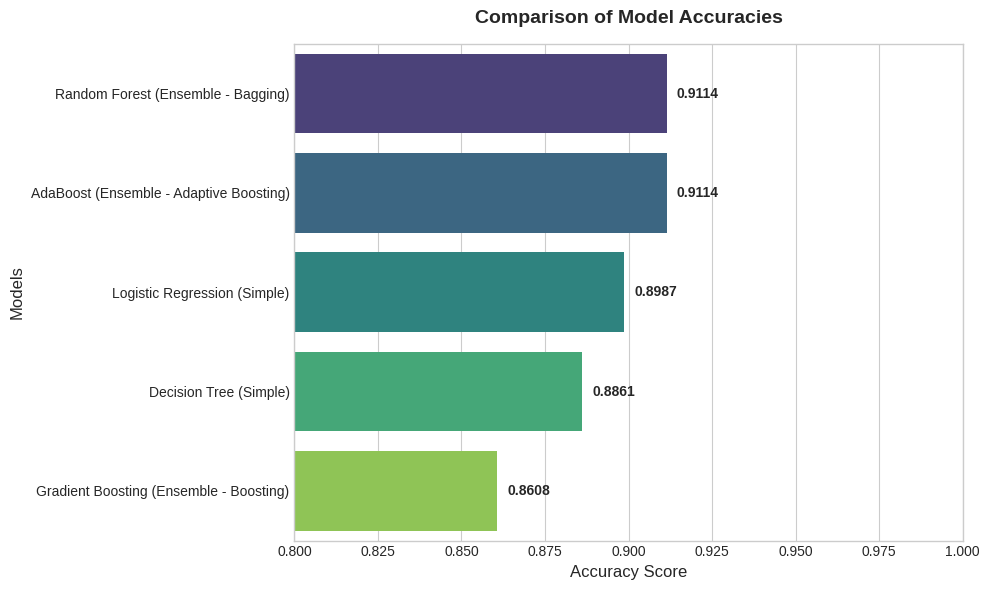

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik stilini ayarlama
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10, 6))

# Sütun grafiği oluşturma
ax = sns.barplot(
    x='Accuracy', y='Model', data=results_df, palette='viridis', hue='Model', legend=False
)

# Grafik başlığı ve etiketler
plt.title(
    'Comparison of Model Accuracies', fontsize=14, fontweight='bold', pad=15
)
plt.xlabel('Accuracy Score', fontsize=12)
plt.ylabel('Models', fontsize=12)
plt.xlim(0.8, 1.0)  # Skorlar 0.8 ile 1.0 arasında olduğu için odaklanıyoruz

# Barların üzerine yüzde/skor değerlerini yazdırma
for p in ax.patches:
  width = p.get_width()
  ax.text(
      width + 0.003,
      p.get_y() + p.get_height() / 2,
      f'{width:.4f}',
      va='center',
      fontsize=10,
      fontweight='bold',
  )

plt.tight_layout()
plt.show()

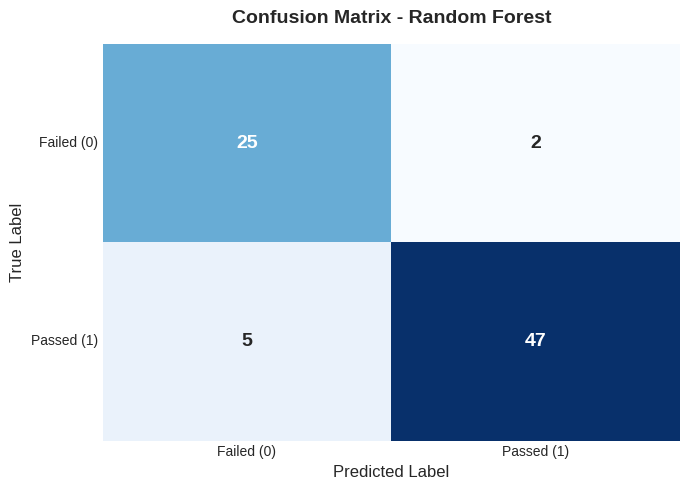

In [9]:
from sklearn.metrics import confusion_matrix

# En iyi modelimizle (örneğin Random Forest veya AdaBoost) tahmin yapalım
# Burada Random Forest'ı seçiyoruz:
best_model = models['Random Forest (Ensemble - Bagging)']
y_pred_best = best_model.predict(X_test_scaled)

# Confusion Matrix hesaplama
cm = confusion_matrix(y_test, y_pred_best)

# Görselleştirme
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    annot_kws={'size': 14, 'weight': 'bold'},
)

plt.title('Confusion Matrix - Random Forest', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks([0.5, 1.5], ['Failed (0)', 'Passed (1)'])
plt.yticks([0.5, 1.5], ['Failed (0)', 'Passed (1)'], rotation=0)

plt.tight_layout()
plt.show()

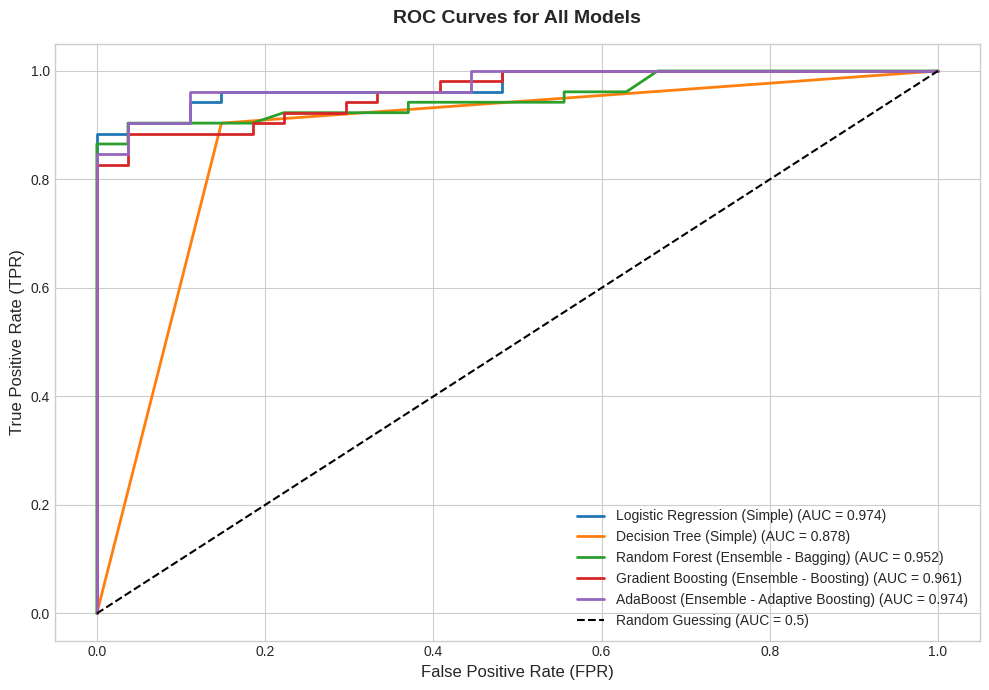

In [10]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))

for name, model in models.items():
  # Olasılık tahminlerini alıyoruz
  y_prob = model.predict_proba(X_test_scaled)[:, 1]
  fpr, tpr, thresholds = roc_curve(y_test, y_prob)
  auc = roc_auc_score(y_test, y_prob)

  plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', linewidth=2)

# Çapraz rastgele tahmin çizgisi (Rastgele tahmin = 0.5)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.5)')

plt.title(
    'ROC Curves for All Models', fontsize=14, fontweight='bold', pad=15
)
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True)

plt.tight_layout()
plt.show()